# Assignment 11: Vision Transformer (ViT) Attention Probing & Interactive Prompt-Based Semantic Segmentation
**Author:** Kristian Hudák  
**Course:** AI Olympiad (OAI) Preparation Course  
**Model:** Pretrained `ViT-B/16` (ImageNet-1k)

This project probes the internal self-attention mechanisms and intermediate patch representations of Vision Transformers:
1. **Model Surgery & Attention Probing:** Dynamically hooking into PyTorch Vision Transformer blocks to intercept multi-head attention weights and layer-wise intermediate embeddings.
2. **Category Probability & Attention Map Inspection:** Extracting layer-by-layer attention patterns for ImageNet classification.
3. **Interactive Prompt-Based Segmentation (SAM-style):** A custom JavaScript overlay in the notebook captures user click prompts on specific object parts (e.g. animal eyes, legs, body).
4. **Max-Similarity Feature Aggregation:** Projecting click coordinates into ViT patch space, calculating high-dimensional cosine similarity across all image patches, and aggregating multi-point semantic maps.
5. **Morphological Post-Processing:** Sharpening, Gaussian blurring, and threshold binarization to generate clean zero-shot segmentation masks.


## 1. Model Loading, Surgery & Attention Map Hooking


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision.models import vit_b_16, ViT_B_16_Weights
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import math
import numpy as np
import cv2
import matplotlib.pyplot as plt


In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)


cuda


In [3]:
# Download pre-trained Vision Transformer (ViT-B/16)
pretrained_weights = ViT_B_16_Weights.IMAGENET1K_V1
model = vit_b_16(weights=pretrained_weights).to(device)


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 191MB/s]


In [4]:
# Patch model forward method to extract attention maps and intermediate embeddings
def layer_forward(self, input: torch.Tensor):
    torch._assert(input.dim() == 3, f"Expected (batch_size, seq_length, hidden_dim) got {input.shape}")
    x = self.ln_1(input)
    normalized_intermediates.append(x.detach().cpu()) # probe
    x, att_map = self.self_attention(x, x, x, need_weights=True, average_attn_weights=False)
    att_maps.append(att_map.detach().cpu()) # probe
    x = self.dropout(x)
    x = x + input
    y = self.ln_2(x)
    y = self.mlp(y)
    o = x + y
    intermediates.append(o.detach().cpu()) # probe
    return o

for layer in model.encoder.layers:
    layer.forward = layer_forward.__get__(layer, type(layer))


In [5]:
import kagglehub
path = kagglehub.dataset_download("ambityga/imagenet100")
print("Path to dataset files:", path)


100%|██████████| 16.1G/16.1G [12:01<00:00, 24.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ambityga/imagenet100/versions/8


## 2. ImageNet Data Ingestion & Classification Inference


In [6]:
# Download ImageNet-1k class labels
!wget http://storage.googleapis.com/bit_models/ilsvrc2012_wordnet_lemmas.txt


--2026-01-28 18:57:24--  http://storage.googleapis.com/bit_models/ilsvrc2012_wordnet_lemmas.txt
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.200.207, 74.125.130.207, 74.125.68.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.200.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 21675 (21K) [text/plain]
Saving to: ‘ilsvrc2012_wordnet_lemmas.txt’

ilsvrc2012_wordnet_ 100%[===================>]  21.17K  --.-KB/s    in 0s      

2026-01-28 18:57:26 (325 MB/s) - ‘ilsvrc2012_wordnet_lemmas.txt’ saved [21675/21675]



In [7]:
imagenet_labels = dict(enumerate(open('ilsvrc2012_wordnet_lemmas.txt')))
print(imagenet_labels)


{0: 'tench, Tinca_tinca\n', 1: 'goldfish, Carassius_auratus\n', 2: 'great_white_shark, white_shark, man-eater, man-eating_shark, Carcharodon_carcharias\n', 3: 'tiger_shark, Galeocerdo_cuvieri\n', 4: 'hammerhead, hammerhead_shark\n', 5: 'electric_ray, crampfish, numbfish, torpedo\n', 6: 'stingray\n', 7: 'cock\n', 8: 'hen\n', 9: 'ostrich, Struthio_camelus\n', 10: 'brambling, Fringilla_montifringilla\n', 11: 'goldfinch, Carduelis_carduelis\n', 12: 'house_finch, linnet, Carpodacus_mexicanus\n', 13: 'junco, snowbird\n', 14: 'indigo_bunting, indigo_finch, indigo_bird, Passerina_cyanea\n', 15: 'robin, American_robin, Turdus_migratorius\n', 16: 'bulbul\n', 17: 'jay\n', 18: 'magpie\n', 19: 'chickadee\n', 20: 'water_ouzel, dipper\n', 21: 'kite\n', 22: 'bald_eagle, American_eagle, Haliaeetus_leucocephalus\n', 23: 'vulture\n', 24: 'great_grey_owl, great_gray_owl, Strix_nebulosa\n', 25: 'European_fire_salamander, Salamandra_salamandra\n', 26: 'common_newt, Triturus_vulgaris\n', 27: 'eft\n', 28: 'sp

In [8]:
!ls -l $path/val.X/n01773549


total 7924
-rw-r--r-- 1 root root   62175 Jan 28 18:57 ILSVRC2012_val_00002688.JPEG
-rw-r--r-- 1 root root   97064 Jan 28 18:57 ILSVRC2012_val_00003431.JPEG
-rw-r--r-- 1 root root   99968 Jan 28 18:57 ILSVRC2012_val_00004271.JPEG
-rw-r--r-- 1 root root   90311 Jan 28 18:57 ILSVRC2012_val_00004335.JPEG
-rw-r--r-- 1 root root   95669 Jan 28 18:57 ILSVRC2012_val_00007224.JPEG
-rw-r--r-- 1 root root   70655 Jan 28 18:57 ILSVRC2012_val_00007882.JPEG
-rw-r--r-- 1 root root   69880 Jan 28 18:57 ILSVRC2012_val_00008316.JPEG
-rw-r--r-- 1 root root   97696 Jan 28 18:57 ILSVRC2012_val_00008352.JPEG
-rw-r--r-- 1 root root  156532 Jan 28 18:57 ILSVRC2012_val_00009216.JPEG
-rw-r--r-- 1 root root   70982 Jan 28 18:57 ILSVRC2012_val_00009558.JPEG
-rw-r--r-- 1 root root   74675 Jan 28 18:57 ILSVRC2012_val_00011638.JPEG
-rw-r--r-- 1 root root  306539 Jan 28 18:57 ILSVRC2012_val_00011677.JPEG
-rw-r--r-- 1 root root   89467 Jan 28 18:57 ILSVRC2012_val_00011808.JPEG
-rw-r--r-- 1 root root  258562 Jan 28 18

In [9]:
imagepath = path + '/val.X/' + 'n01773549' +'/' + 'ILSVRC2012_val_00008316.JPEG'


In [10]:
from google.colab import files
files.download(imagepath)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

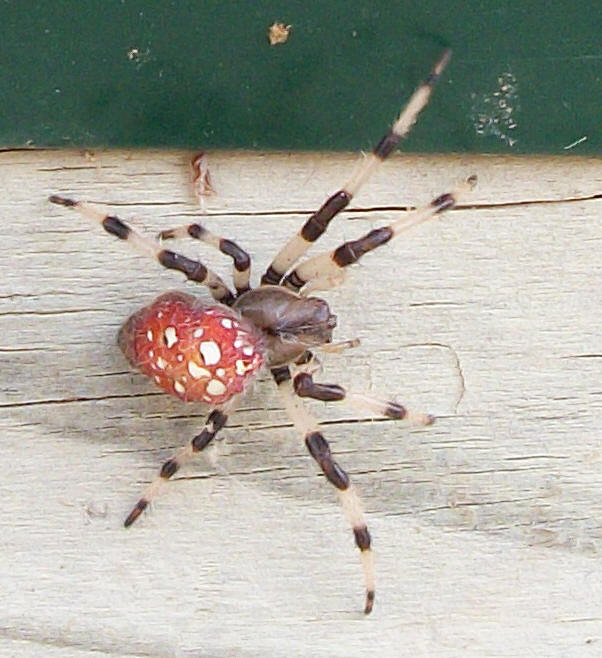

In [11]:
import cv2
image = cv2.imread(imagepath)
from google.colab.patches import cv2_imshow
cv2_imshow(image)


In [12]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])


In [13]:
size = (224, 224)


In [14]:
blob = transform(cv2.resize(cv2.cvtColor(image,cv2.COLOR_BGR2RGB),size)).unsqueeze(0).to(device)


In [15]:
blob.shape


torch.Size([1, 3, 224, 224])

In [16]:
with torch.no_grad():
    att_maps = []
    intermediates = []
    normalized_intermediates = []
    logits = model(blob)


In [17]:
# Compute and display top category probabilities
probabilities = torch.sigmoid(logits)[0]
labels = torch.argsort(probabilities, dim=-1, descending=True)
top5 = labels[:5]
print("Prediction:")
for idx in top5:
    print(f'{probabilities[idx.item()]:.5f} : {imagenet_labels[idx.item()]}', end='')


Prediction:
0.99987 : garden_spider, Aranea_diademata
0.99986 : barn_spider, Araneus_cavaticus
0.99800 : wolf_spider, hunting_spider
0.99232 : spider_web, spider's_web
0.98972 : tarantula


In [18]:
att_maps = torch.cat(att_maps, dim=0)
intermediates = torch.cat(intermediates, dim=0)
normalized_intermediates = torch.cat(normalized_intermediates, dim=0)


In [19]:
print(att_maps.shape)
print(intermediates.shape)
print(normalized_intermediates.shape)


torch.Size([12, 12, 197, 197])
torch.Size([12, 197, 768])
torch.Size([12, 197, 768])


In [20]:
def draw_mask(img, mask):
    H, W = img.shape[:2]
    mask_resized = cv2.resize(mask, (W, H), interpolation=cv2.INTER_LINEAR)
    if img.ndim == 3:
        mask_resized = np.repeat(mask_resized[:, :, None], 3, axis=2)
    result = (img.astype(np.float32) * mask_resized).clip(0, 255).astype(np.uint8)
    return result


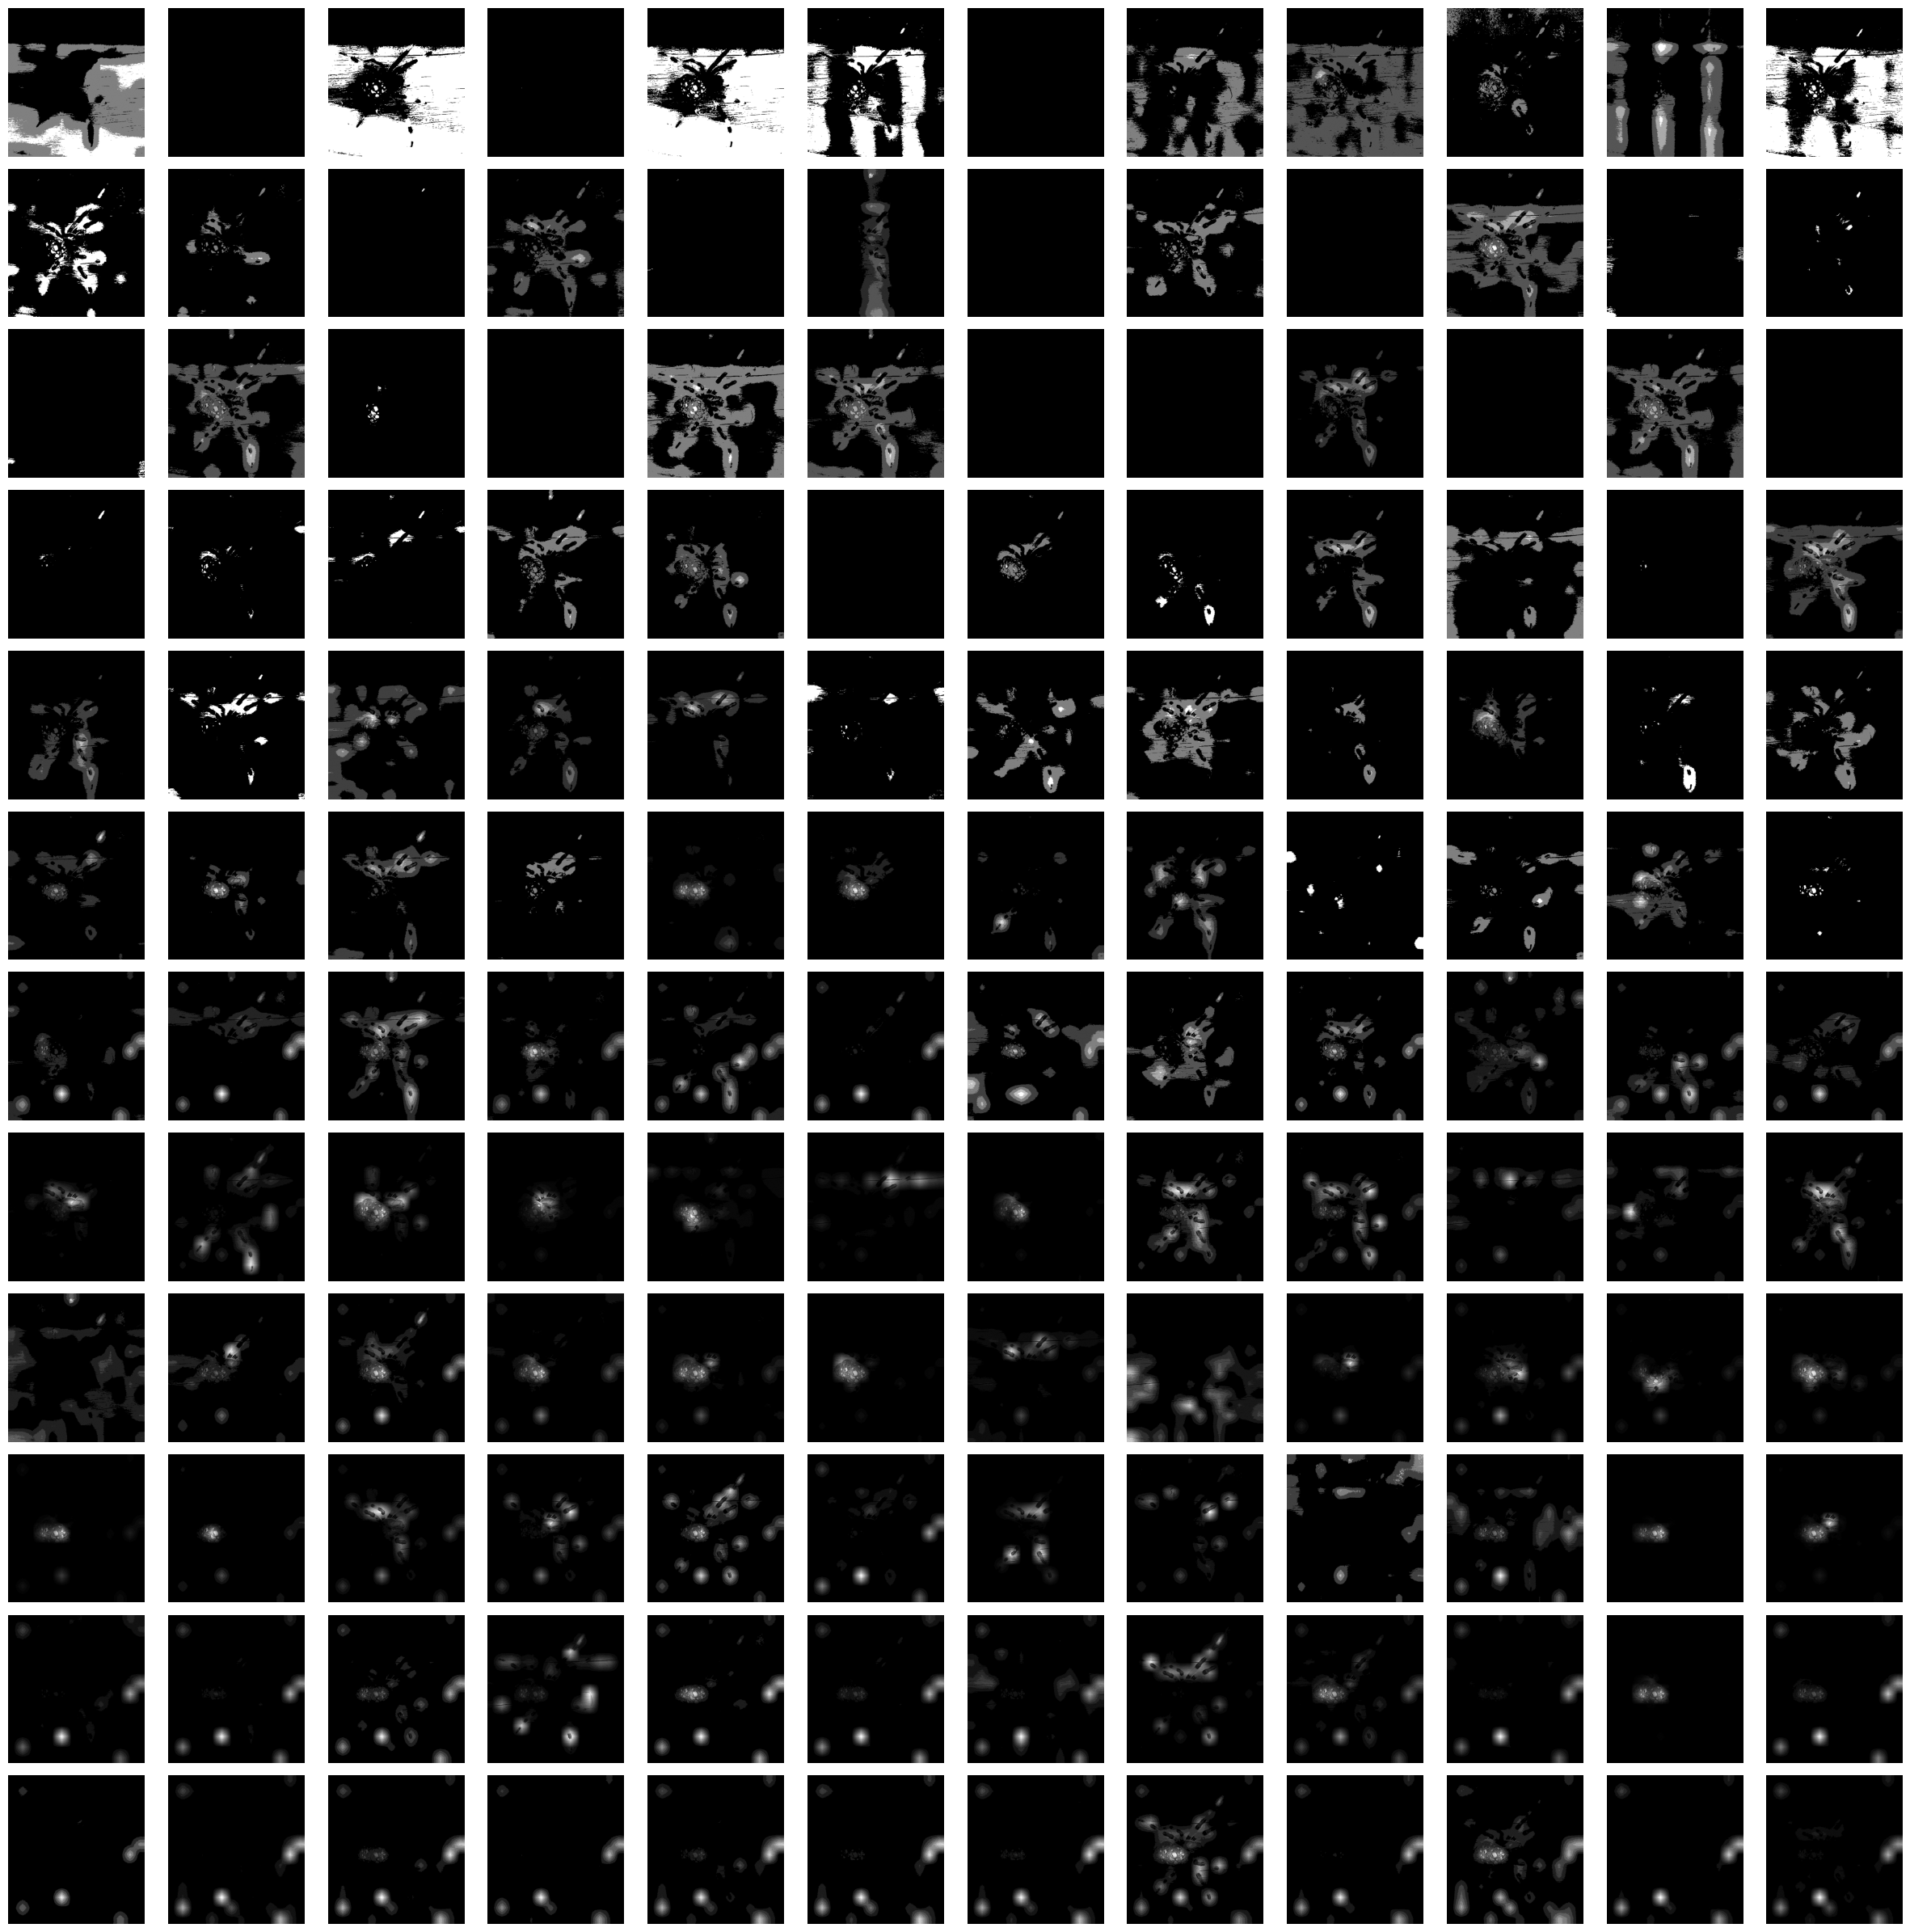

In [21]:
base = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
num_layers, num_heads, N, _ = att_maps.shape
patch_size = int(math.sqrt(size[0]*size[1]//(N-1)))
att_size = (size[0]//patch_size, size[1]//patch_size)
plt.figure(figsize=(2 * num_heads, 2 * num_layers))
for t in range(num_layers):
    for i in range(num_heads):
        head = att_maps[t, i]
        mask = head[0, 1:].reshape(att_size[0], att_size[1])
        mask = mask.detach().cpu().numpy()
        disp = draw_mask(base, mask)
        plt.subplot(num_layers, num_heads, t * num_heads + i + 1)
        plt.imshow(disp, cmap='gray')
        plt.axis('off')
plt.tight_layout()
plt.show()


## 3. Interactive Point-Prompt Semantic Segmentation Pipeline

Capturing point prompts via JavaScript click overlay, mapping coordinates to ViT patch tokens, computing cosine similarity against intermediate layer embeddings, and extracting object masks.


In [22]:
# Custom prompt-based semantic segmentation: finding image regions semantically matching click prompts


In [23]:

from IPython.display import display, HTML, clear_output
import base64
from PIL import Image
import io
import os
import random

# --- QUALITY & FILTER PARAMETERS ---
threshold = 0.40       # Prah pre binarizáciu (nižší = zachytí viac detailov)
layer_to_probe = 9     # Vrstva 9-10 býva najcitlivejšia na sémantiku objektov
num_clicks = 3         # Štandardný počet kliknutí pre experimenty
sharpening_factor = 4  # Koeficient zaostrenia mapy podobnosti
aggregation_method = 'max' # Metóda spájania viacerých bodov ('max' je super na členité objekty)


In [24]:
def get_single_click(img_path, click_number=1, total_clicks=3):
    """Získanie súradníc jedného kliknutia cez JavaScript overlay"""#toto mi prislo ako najlepsie riesenie kliknutia a nejjednoduchsie
    img = Image.open(img_path).convert("RGB").resize((224, 224))
    buffered = io.BytesIO()
    img.save(buffered, format="JPEG")
    img_str = base64.b64encode(buffered.getvalue()).decode()

    html_code = f"""
    <div style="font-family: sans-serif; margin-bottom: 10px;"><b>Kliknutie {click_number}/{total_clicks}:</b> Klikni na objekt.</div>
    <div id="wrapper" style="position: relative; display: inline-block;">
        <img id="target_image" src="data:image/jpeg;base64,{img_str}" style="cursor: crosshair; border: 2px solid #333;">
    </div>
    <script>
    window.getSingleClickPromise = function() {{
        return new Promise((resolve) => {{
            const img = document.getElementById('target_image');
            img.onclick = (e) => {{
                const rect = img.getBoundingClientRect();
                resolve({{x: Math.round(e.clientX - rect.left), y: Math.round(e.clientY - rect.top)}});
            }};
        }});
    }};
    </script>
    """
    display(HTML(html_code))
    return output.eval_js("window.getSingleClickPromise()")

def compute_similarity_map(intermediates, layer_idx, px, py, sharpening=4):
    """Výpočet kosínovej podobnosti medzi vybraným bodom a zvyškom obrazu"""
    patch_idx = (py // 16 * 14 + px // 16) + 1 # Prepočet pixelov na index patchu (14x14 grid)
    query_vec = intermediates[layer_idx, patch_idx, :].unsqueeze(0) # Vektor príznakov v bode kliku

    all_patches = intermediates[layer_idx, 1:, :] # Všetky patche (bez CLS tokenu)
    sim = F.cosine_similarity(all_patches, query_vec, dim=1)
    sim_map = sim.reshape(14, 14).detach().cpu().numpy()

    # Normalization and sharpening filter
    sim_map = (sim_map - sim_map.min()) / (sim_map.max() - sim_map.min() + 1e-8)
    return cv2.resize(sim_map ** sharpening, (224, 224), interpolation=cv2.INTER_CUBIC)

def aggregate_similarity_maps(maps, method='max'):
    """Spojenie viacerých máp (z viacerých klikov) do jednej"""
    return np.max(maps, axis=0) if method == 'max' else np.mean(maps, axis=0)

def apply_morphological_operations(mask, kernel_size=5):
    """Vyčistenie šumu a vyhladenie okrajov masky"""
    mask_uint8 = (mask * 255).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    cleaned = cv2.morphologyEx(mask_uint8, cv2.MORPH_CLOSE, kernel) # Vyplnenie dier
    return cv2.morphologyEx(cleaned, cv2.MORPH_OPEN, kernel).astype(np.float32) / 255.0


 Spracovávam: /root/.cache/kagglehub/datasets/ambityga/imagenet100/versions/8/val.X/n01675722/ILSVRC2012_val_00037626.JPEG



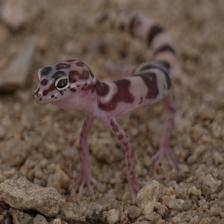

In [28]:
import os
from IPython.display import display, HTML, clear_output
import base64
from PIL import Image
import io
from google.colab import output

# Re-defining get_multi_click function (from a previous version)
def get_multi_click(img_path, n=3):
    img = Image.open(img_path).convert("RGB").resize((224, 224))
    buffered = io.BytesIO()
    img.save(buffered, format="JPEG")
    img_str = base64.b64encode(buffered.getvalue()).decode()
    html_code = f"""
    <div style="font-family: sans-serif; margin-bottom: 10px;"><b>Inštrukcia:</b> Klikni <b>{{n}}x</b>. Skús trafiť telo aj najtenšie nohy.</div>
    <div id="wrapper" style="position: relative; display: inline-block;">
        <img id="target_image" src="data:image/jpeg;base64,{img_str}" style="cursor: crosshair; border: 2px solid #333;">
    </div>
    <p id="status">Čakám na kliknutie 1/{{n}}...</p>
    <script>
    // Define a global function that returns a Promise for the clicks
    window.getMultiClicksPromise = function() {{
        return new Promise((resolve) => {{
            const img = document.getElementById('target_image');
            const status = document.getElementById('status');
            let clicks = [];

            if (!img) {{
                console.error("Image element not found during promise creation.");
                resolve([]); // Resolve with empty array or handle error appropriately
                return;
            }}

            img.onclick = (e) => {{
                const rect = img.getBoundingClientRect();
                const x = Math.round(e.clientX - rect.left);
                const y = Math.round(e.clientY - rect.top);
                clicks.push({{x: x, y: y}});
                const dot = document.createElement('div');
                dot.style.cssText = `position:absolute; left:${{x-3}}px; top:${{y-3}}px; width:6px; height:6px; background:red; border-radius:50%;`;
                document.getElementById('wrapper').appendChild(dot);
                if (clicks.length < {n}) status.innerText = `Čakám na kliknutie ${{clicks.length + 1}}/{n}...`;
                else {{
                    img.onclick = null; // Disable further clicks after all clicks are made
                    resolve(clicks);
                }}
            }};
        }});
    }};
    </script>
    """
    display(HTML(html_code))
    return output.eval_js("window.getMultiClicksPromise()")

# --- PIPELINE SETUP ---
target_file = 'ILSVRC2012_val_00037626.JPEG'
imagepath = None

# 1. Locate image in dataset
for root, dirs, files in os.walk(os.path.join(path, 'val.X')):
    if target_file in files:
        imagepath = os.path.join(root, target_file)
        break

if imagepath is None:
    print(f" Súbor {target_file} sa nenašiel! Skontroluj, či je dataset správne pripojený.")
else:
    print(f" Spracovávam: {imagepath}")

    # 2. Forward pass to obtain fresh intermediate layer activations
    image = cv2.imread(imagepath)
    img_rgb_full = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    blob = transform(cv2.resize(img_rgb_full, (224, 224))).unsqueeze(0).to(device)

    with torch.no_grad():
        att_maps = [] # Re-initialize as list
        intermediates = [] # Re-initialize as list
        normalized_intermediates = [] # Re-initialize as list
        model(blob)
    intermediates_tensor = torch.cat(intermediates, dim=0)

    # 3. Interactive prompt collection (3 points)
    # Recommended: Click on the object head and at least once on a limb
    coords = get_multi_click(imagepath, n=num_clicks)


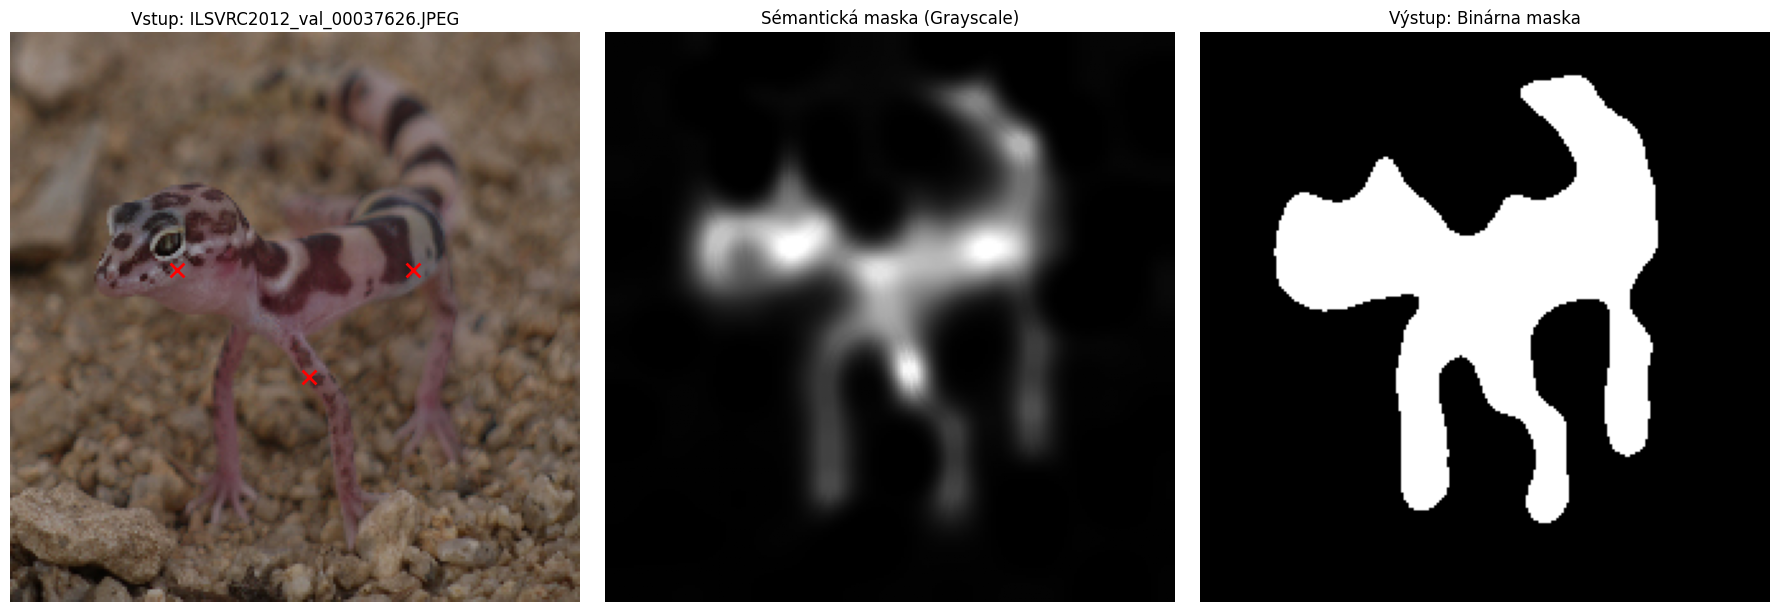

In [29]:
if not coords:
    print("No click coordinates were recorded.")
else:
    # 1. Compute cosine similarity for each clicked prompt point
    query_vectors = [intermediates_tensor[layer_to_probe, (c['y'] // 16 * 14 + c['x'] // 16) + 1, :] for c in coords]
    all_patches = intermediates_tensor[layer_to_probe, 1:, :]

    similarities = [F.cosine_similarity(all_patches, q_vec.unsqueeze(0), dim=1) for q_vec in query_vectors]

    # 2. Max-similarity aggregation across multi-point prompts
    max_sim, _ = torch.stack(similarities).max(dim=0)
    sim_map = max_sim.reshape(14, 14).detach().cpu().numpy()

    # 3. Post-processing and noise cleaning
    sim_upsampled = cv2.resize(sim_map, (224, 224), interpolation=cv2.INTER_CUBIC)
    # Sharpen semantic feature map
    sim_sharpened = np.clip(sim_upsampled ** sharpening_factor, 0, 1)

    # Morphological opening to remove noise
    mask_cleaned = apply_morphological_operations(sim_sharpened, kernel_size=5)

    # Binarization thresholding (0.1 to retain fine details)
    binary_mask = (mask_cleaned > 0.1).astype(np.uint8) * 255

    # 4. Final visualization
    plt.figure(figsize=(18, 6))

    # Subplot 1: Input image with prompt points
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.resize(img_rgb_full, (224, 224)))
    for c in coords:
        plt.scatter(c['x'], c['y'], c='red', s=100, marker='x', linewidths=2)
    plt.title(f"Vstup: {target_file}")
    plt.axis('off')

    # Subplot 2: Continuous semantic feature heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(mask_cleaned, cmap='gray')
    plt.title("Sémantická maska (Grayscale)")
    plt.axis('off')

    # Subplot 3: Extracted binary segmentation mask
    plt.subplot(1, 3, 3)
    plt.imshow(binary_mask, cmap='gray')
    plt.title("Výstup: Binárna maska")
    plt.axis('off')

    plt.tight_layout()
    plt.show()




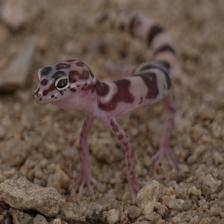

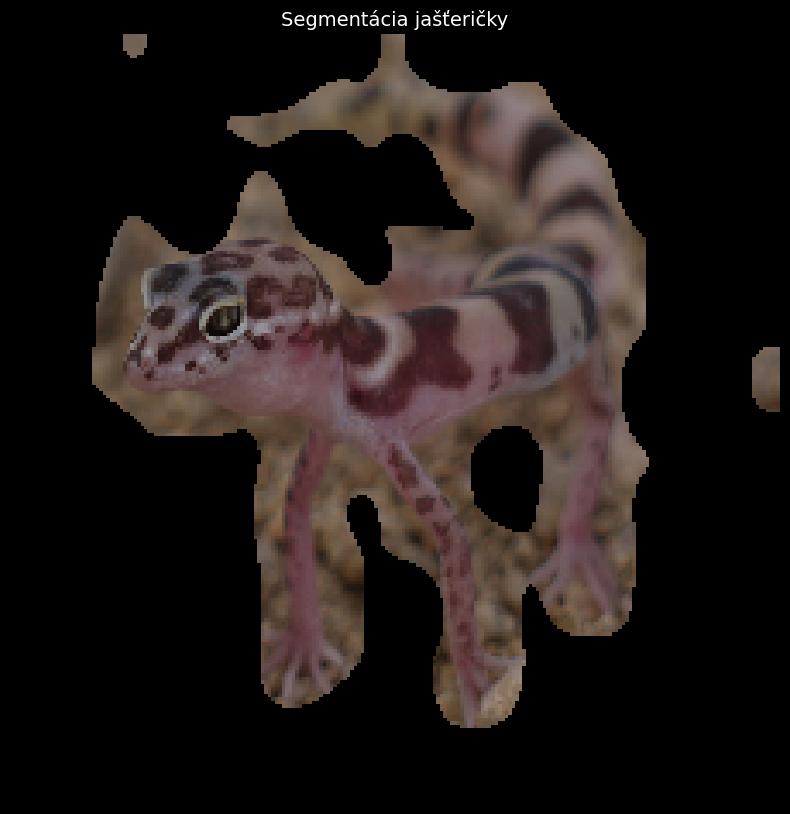

In [30]:


# --- 1. IMAGE SEARCH & PREPARATION ---
target_file = 'ILSVRC2012_val_00037626.JPEG'
imagepath = None

for root, dirs, files in os.walk(os.path.join(path, 'val.X')):
    if target_file in files:
        imagepath = os.path.join(root, target_file)
        break

if imagepath is None:
    print(f"Súbor {target_file} sa nenašiel!")
else:
    # Set model to eval mode and extract feature vectors
    model.eval()
    image = cv2.imread(imagepath)
    img_rgb_224 = cv2.resize(cv2.cvtColor(image, cv2.COLOR_BGR2RGB), (224, 224))
    blob = transform(img_rgb_224).unsqueeze(0).to(device)

    with torch.no_grad():
        intermediates = [] # Hooky naplnia tento list
        model(blob)
    intermediates_tensor = torch.cat(intermediates, dim=0)

    # --- 2. INTERACTIVE PROMPT COLLECTION ---
    # Tip: Click on each kitten at least once
    coords = get_multi_click(imagepath, n=num_clicks)

    if coords:
        # --- 3. COMPUTE MAX-SIMILARITY SEGMENTATION ---
        query_vectors = [intermediates_tensor[layer_to_probe, (c['y'] // 16 * 14 + c['x'] // 16) + 1, :] for c in coords]
        all_patches = intermediates_tensor[layer_to_probe, 1:, :]

        # Compare every spatial patch embedding against all prompt vectors
        similarities = [F.cosine_similarity(all_patches, q_vec.unsqueeze(0), dim=1) for q_vec in query_vectors]
        max_sim, _ = torch.stack(similarities).max(dim=0)

        # --- 4. FOREGROUND MASKING & ALPHA COMPOSITING ---
        sim_map = max_sim.reshape(14, 14).detach().cpu().numpy()
        mask = cv2.resize(sim_map, (224, 224), interpolation=cv2.INTER_CUBIC)

        # Binarization and Gaussian blur for smooth boundary transitions
        binary_mask = (mask > threshold).astype(np.float32)
        binary_mask = cv2.GaussianBlur(binary_mask, (7, 7), 0)
        binary_mask = (binary_mask > 0.5).astype(np.float32)

        # Apply binary mask to RGB image (zeroing out background)
        final_reveal = (img_rgb_224.astype(np.float32) / 255.0) * binary_mask[..., None]

        # --- 5. VISUALIZATION ---
        plt.figure(figsize=(10, 10))
        plt.imshow(final_reveal)
        plt.title(f"Segmentácia jašťeričky", color='white', fontsize=14)
        plt.axis('off')
        # Plotting segmented subject on clean black background
        plt.gcf().set_facecolor('black')
        plt.show()



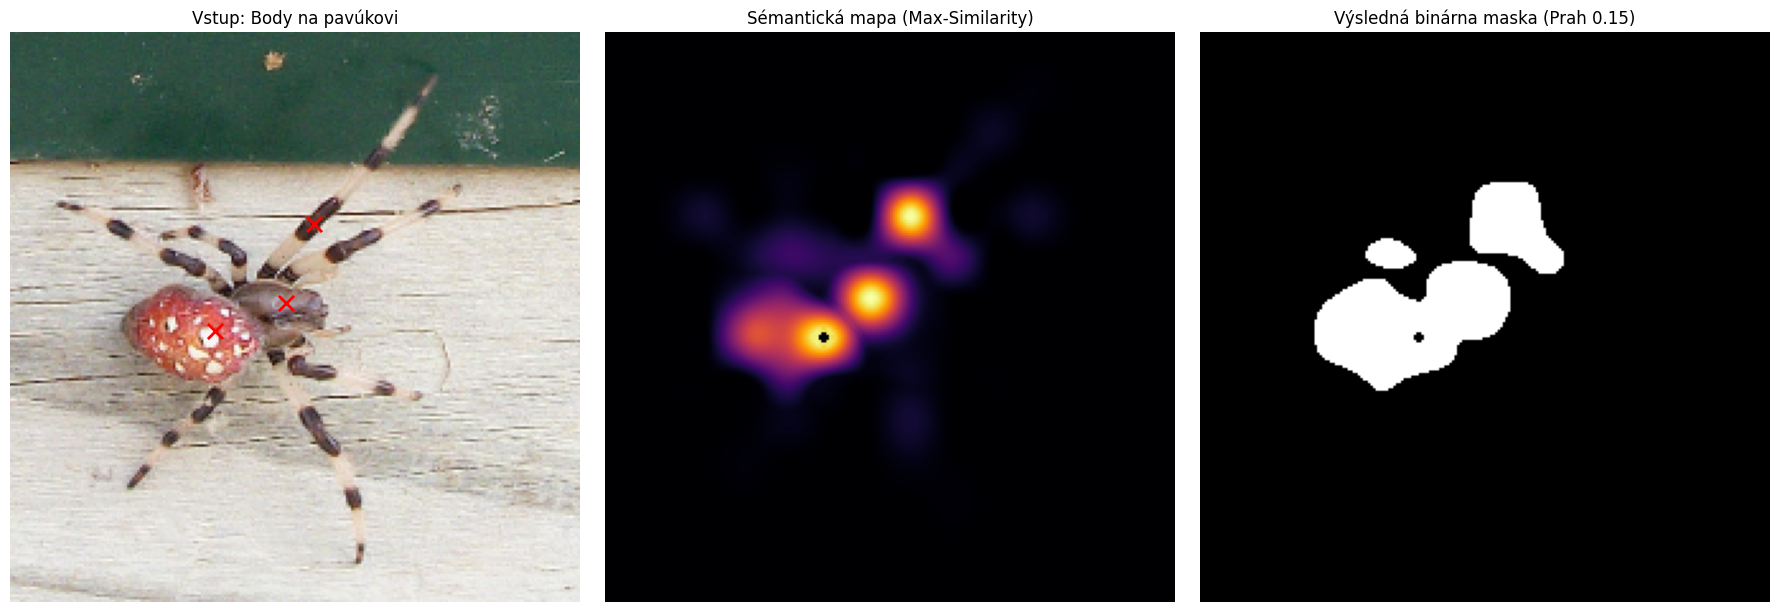

In [31]:
# EXPERIMENT: PROMPT-BASED SPIDER SEGMENTATION
target_file = 'ILSVRC2012_val_00008316.JPEG'
imagepath = None

# 1. Image retrieval
for root, dirs, files in os.walk(os.path.join(path, 'val.X')):
    if target_file in files:
        imagepath = os.path.join(root, target_file)
        break

if imagepath is None:
    print(f"Chyba: Súbor {target_file} sa v datasete nenašiel! Skontroluj cestu k dátam.")
else:
    print(f"Súbor nájdený: {imagepath}")

    # 2. Data preparation and model forward pass
    image = cv2.imread(imagepath)
    img_rgb_full = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    # Resize to 224x224 for ViT-B/16 input
    blob = transform(cv2.resize(img_rgb_full, (224, 224))).unsqueeze(0).to(device)

    with torch.no_grad():
        intermediates = [] # Resetujeme zoznam pre zachytenie aktivácií
        model(blob) # Model počas behu naplní list 'intermediates' cez hooky

    # Convert intermediate list to tensor: (layers, patches, dim)
    intermediates_tensor = torch.cat(intermediates, dim=0)

    # 3. Interactive prompt collection
    # TIP: Click the center body and two distinct legs
    clicks = []
    similarity_maps = []

    for i in range(num_clicks):
        clear_output(wait=True)
        print(f"Segmentácia pavúka: {target_file}")
        c = get_single_click(imagepath, click_number=i+1, total_clicks=num_clicks)
        px, py = c['x'], c['y']
        clicks.append((px, py))

        # Compute similarity heatmap for prompt point
        sim_map = compute_similarity_map(
            intermediates_tensor,
            layer_to_probe,
            px, py,
            sharpening=sharpening_factor
        )
        similarity_maps.append(sim_map)

    # 4. Max-aggregation and binarization
    # 'Max' aggregation ensures that if a patch matches ANY prompt point, it is retained in the mask.
    final_sim = aggregate_similarity_maps(similarity_maps, method='max')
    final_sim_cleaned = apply_morphological_operations(final_sim, kernel_size=3)

    # Threshold 0.15 calibrated to preserve fine leg structures
    spider_threshold = 0.15
    binary_mask = (final_sim_cleaned > spider_threshold).astype(np.uint8) * 255

    # 5. Display segmentation results
    clear_output(wait=True)
    plt.figure(figsize=(18, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.resize(img_rgb_full, (224, 224)))
    for x, y in clicks:
        plt.scatter(x, y, c='red', s=120, marker='x', linewidths=2)
    plt.title("Vstup: Body na pavúkovi")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(final_sim_cleaned, cmap='inferno')
    plt.title("Sémantická mapa (Max-Similarity)")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(binary_mask, cmap='gray')
    plt.title(f"Výsledná binárna maska (Prah {spider_threshold})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()



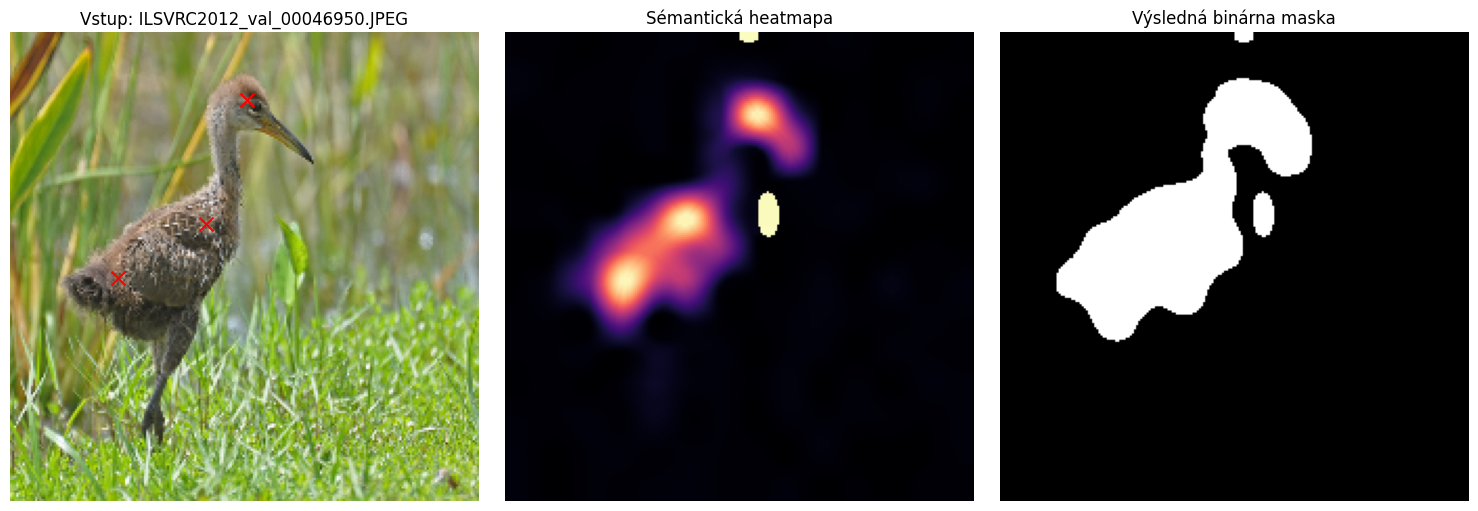

Segmentácia dokončená pre náhodný objekt.


In [33]:

from IPython.display import clear_output

# --- 1. RANDOM IMAGE BENCHMARK ---
# Select random sample from validation split
all_images = []
classes_path = os.path.join(path, 'val.X')

for root, dirs, files in os.walk(classes_path):
    for file in files:
        if file.lower().endswith(('.jpeg', '.jpg', '.png')):
            all_images.append(os.path.join(root, file))

if not all_images:
    print("Chyba: Nenašli sa žiadne obrázky. Skontroluj premennú 'path'.")
else:
    imagepath = random.choice(all_images)
    print(f" Vybraný náhodný obrázok: {os.path.basename(imagepath)}")
    print(f"Zložka: {os.path.dirname(imagepath).split('/')[-1]}")

    # --- 2. DATA PREPARATION ---
    image = cv2.imread(imagepath)
    img_rgb_full = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    # Transform and move to GPU
    blob = transform(cv2.resize(img_rgb_full, (224, 224))).unsqueeze(0).to(device)

    # Extract semantic patch embeddings
    with torch.no_grad():
        intermediates = [] # Reset listu (predpokladáme, že hooky sú nastavené)
        model(blob)

    # Convert to tensor (num_layers, num_patches, hidden_dim)

    intermediates_tensor = torch.cat(intermediates, dim=0) if isinstance(intermediates, list) else intermediates

    # --- 3. INTERACTIVE CLICK COLLECTION ---
    clicks = []
    similarity_maps = []

    for i in range(num_clicks):
        clear_output(wait=True)
        print(f"Spracovávam náhodný obrázok: {os.path.basename(imagepath)}")
        print(f"Klikni na objekt, ktorý chceš segmentovať ({i+1}/{num_clicks})")

        c = get_single_click(imagepath, click_number=i+1, total_clicks=num_clicks)
        px, py = c['x'], c['y']
        clicks.append((px, py))

        # Compute similarity map for click
        sim_map = compute_similarity_map(
            intermediates_tensor,
            layer_to_probe,
            px, py,
            sharpening=sharpening_factor
        )
        similarity_maps.append(sim_map)

    # --- 4. AGGREGATION & FINAL RENDERING ---
    # Max pooling fuses disparate regions (e.g. ear, torso, paw) into a single cohesive mask
    final_sim = aggregate_similarity_maps(similarity_maps, method='max')
    final_sim_cleaned = apply_morphological_operations(final_sim, kernel_size=5)

    # Binarization thresholding
    binary_mask = (final_sim_cleaned > 0.1).astype(np.uint8) * 255

    clear_output(wait=True)
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.resize(img_rgb_full, (224, 224)))
    for x, y in clicks:
        plt.scatter(x, y, c='red', s=100, marker='x')
    plt.title(f"Vstup: {os.path.basename(imagepath)}")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(final_sim_cleaned, cmap='magma')
    plt.title("Sémantická heatmapa")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(binary_mask, cmap='gray')
    plt.title("Výsledná binárna maska")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    print(f"Segmentácia dokončená pre náhodný objekt.")
